# Droughts in Catalonia: from rainfall deficit to empty reservoirs to official drought status

## 1. Libraries and configuration

In [1]:
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap

warnings.filterwarnings("ignore")

In [2]:
import requests

# ---- Paths ----
XEMA_URL = "https://analisi.transparenciacatalunya.cat/resource/7bvh-jvq2.json"
XEMA_CSV = os.path.join("..", "data", "raw", "xema_daily_precip.csv")   # cache, created on first run
XEMA_PPT_CODE = "1300"                      # XEMA variable: daily precipitation (check it is the midnight-to-midnight one, not the 8-8h variant)
DATA_DIRS = ["../data", "../data/raw", "data", ".", ".."]

OUT_DIR = "../data"                         # folder for the CSV outputs (repo data folder)
FIG_DIR = "../figures/Nuria"                # folder for the PNG figures (repo figures folder, Núria's subfolder)
os.makedirs(OUT_DIR, exist_ok=True); os.makedirs(FIG_DIR, exist_ok=True)

# ---- Shared team files ----
COMARQUES_JSON = "divisions-administratives-v2r1-comarques-250000-20250730.json"
COMARQUES_GLOB = "divisions-administratives*comarques*.json"   # fallback if the date/version in the name differs
MUNIS_JSON = "divisions-administratives-v2r1-municipis-1000000-20250730.json"
MUNIS_GLOB = "divisions-administratives*municipis*.json"
USE_GEO = True                                # False skips everything that needs geopandas / shapely

# ---- Study parameters ----
UNIT_KEY = "terllobregat"                     # reference unit "Embassament Ter- Llobregat" (matched ignoring spaces/hyphens)
SYSTEM_RX = r"\bsau\b|susqueda|baells|llosa del cavall|sant pon"   # reservoirs of that unit
CATCHMENT = ["Ripollès", "Osona", "Berguedà", "Bages", "Garrotxa", "Selva", "Gironès", "Anoia", "Moianès",
             "Vallès Occidental", "Vallès Oriental", "Maresme", "Baix Llobregat", "Alt Penedès", "Garraf",
             "Barcelonès", "Alt Empordà", "Baix Empordà", "Pla de l'Estany", "Solsonès"]   # comarques feeding the system
DROP_COMARQUES = ["Moianès", "Lluçanès"]      # excluded from the comarca table (same as the crops block)
SPI_WINDOW = 6                                # months of accumulated rainfall
DRY_SPI = -1.0                                # SPI-6 <= -1 means a dry month
MIN_DRY_M = 3                                 # an episode starts after 3 consecutive dry months
WET_END_M = 3                                 # ... and ends after 3 consecutive months with SPI-6 > 0
RES_ALERT = 40                                # reservoir level (%) used as the alert threshold
RES_XY = {r"\bsau\b": ("Sau", 2.40, 41.97, -10, -30, "right"), r"susqueda": ("Susqueda", 2.46, 41.98, 10, 6, "left"),
          r"baells": ("La Baells", 1.83, 42.22, 10, 6, "left"), r"llosa": ("Llosa del Cavall", 1.64, 42.10, -10, 8, "right"),
          r"sant pon": ("Sant Ponç", 1.56, 41.97, -10, -30, "right")}   # approximate dam positions, for the map only

### 1.1 Colour palette and plot style (colour-blind safe)

In [3]:
# Okabe-Ito / ColorBrewer colours: blue = water / wetter, orange to brown = drier / more severe. No red, no red-green pairs.
BLUE, SKY, ORANGE, BROWN, GREY = "#0072B2", "#56B4E9", "#E69F00", "#993404", "#6E6E6E"

# Official hydrological status (sequential, light -> dark = more severe)
HYD = {0: ("Normal", "#EDEDED"), 1: ("Pre-alert", "#FFF7BC"), 2: ("Alert", "#FEC44F"), 3: ("Exceptionality", "#EC7014"),
       4: ("Pre-emergency", "#993404"), 5: ("Emergency", "#662506"), 6: ("Emergency II", "#4A1A04"), 7: ("Emergency III", "#2B0F02")}
# Official rainfall status
PLU = {0: ("Normal", "#EDEDED"), 1: ("Moderate drought", "#FFF7BC"), 2: ("Severe drought", "#EC7014"), 3: ("Extreme drought", "#662506")}
# Rainfall anomaly: dry (brown/orange) -> normal (white) -> wet (blue)
DRY_WET = LinearSegmentedColormap.from_list("dry_wet", ["#7F3B08", ORANGE, "#F7F7F7", SKY, "#08519C"])

plt.rcParams.update({"figure.dpi": 110, "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold",
                     "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False, "axes.spines.right": False})

## 2. Helper functions

In [4]:
SOCRATA = "https://analisi.transparenciacatalunya.cat/resource/{}.csv?$limit=1000000"
load = lambda ds: pd.read_csv(SOCRATA.format(ds), low_memory=False).rename(columns=str.upper)

def pick(df, *names):
    """First existing column among the candidates (clear error if none)."""
    for n in names:
        if n in df.columns:
            return n
    raise KeyError(f"None of {names} found. Columns: {list(df.columns)}")

def find(df, rx):
    """First column matching a regex, ignoring code columns (we want names)."""
    cols = [c for c in df.columns if re.search(rx, c, re.I) and "CODI" not in c.upper()]
    if not cols:
        raise KeyError(f"No column matches '{rx}'. Columns: {list(df.columns)}")
    return cols[0]

import glob
def find_file(*names):
    """Look for a shared file in DATA_DIRS (and one sub-folder deep). Each name can be exact or a wildcard pattern; the first hit wins. None if not found."""
    for name in names:
        for d_ in DATA_DIRS:
            for pat in (os.path.join(d_, name), os.path.join(d_, "*", name)):
                hits = sorted(glob.glob(pat))
                if hits:
                    return hits[0]
    return None

def months_between(a, b):
    return (b.year - a.year) * 12 + b.month - a.month

def lvl_hyd(x):
    """Official hydrological status -> ordinal: 0 normal, 1 pre-alert, 2 alert, 3 exceptionality, 4 pre-emergency, 5/6/7 emergency (I/II/III)."""
    x = str(x).lower()
    if "prealerta" in x: return 1
    if "preemerg" in x: return 4
    if "alerta" in x: return 2
    if "excepcional" in x: return 3
    if "emerg" in x:
        m = re.search(r"emerg\w*\s*(iii|ii|i)\b", x)
        return {"i": 5, "ii": 6, "iii": 7}[m.group(1) if m else "i"]
    return 0 if "normal" in x else np.nan

def lvl_plu(x):
    """Official rainfall status -> ordinal: 0 normal, 1 moderate, 2 severe, 3 extreme."""
    x = str(x).lower()
    for k, v in (("extrem", 3), ("sever", 2), ("moderad", 1), ("normal", 0)):
        if k in x: return v
    return np.nan

def run_blocks(s):
    """Contiguous runs of equal value in a monthly series -> [(start, end, value)]."""
    s = s.dropna()
    if s.empty:
        return []
    return [(g.index[0], g.index[-1] + pd.DateOffset(months=1), int(g.iloc[0])) for _, g in s.groupby((s != s.shift()).cumsum())]

## 3. Loading the raw data

### 3.1 XEMA daily precipitation

In [5]:
def download_xema_precip(path=XEMA_CSV, page=50_000):
    """Download daily precipitation of all stations through the API, page by page, and save it as CSV."""
    rows, offset = [], 0
    while True:
        r = requests.get(XEMA_URL, timeout=120, params={
            "$select": "data_lectura, codi_estacio, valor",
            "$where": f"codi_variable = '{XEMA_PPT_CODE}'",
            "$order": "data_lectura, codi_estacio",      # stable order, needed for paging
            "$limit": page, "$offset": offset})
        r.raise_for_status()
        chunk = r.json()
        if not chunk:
            break
        rows += chunk; offset += page
        print(f"\r{len(rows):,} rows", end="")
    os.makedirs(os.path.dirname(path), exist_ok=True)
    pd.DataFrame(rows).to_csv(path, index=False)

if not os.path.exists(XEMA_CSV):
    download_xema_precip()          # first run only: needs internet, several minutes
xema_raw = pd.read_csv(XEMA_CSV, dtype=str)
print(f"XEMA: {len(xema_raw):,} daily-precipitation rows")

XEMA: 1,853,212 daily-precipitation rows


### 3.2 Station metadata, reservoirs and official drought status (Dades Obertes API)

In [6]:
stations = load("yqwd-vj5e")       # XEMA station metadata (comarca, coordinates)
res_raw = load("gn9e-3qhr")        # ACA reservoirs of the Internal Basins (daily)
sq_raw = load("i5n8-43cw")         # ACA official drought status (change log per municipality)

pd.DataFrame({"rows": [len(xema_raw), len(stations), len(res_raw), len(sq_raw)]},
             index=["XEMA precipitation", "Station metadata", "Reservoirs", "Official drought status"])

,rows
XEMA precipitation,1853212
Station metadata,245
Reservoirs,88417
Official drought status,8677


## 4. Cleaning and transformation

### 4.1 XEMA: clean daily precipitation

In [7]:
daily = pd.DataFrame({"station": xema_raw.codi_estacio,
                      "date": pd.to_datetime(xema_raw.data_lectura, errors="coerce").dt.normalize(),
                      "ppt": pd.to_numeric(xema_raw.valor, errors="coerce")}).dropna(subset=["date"])
daily.loc[daily.ppt < 0, "ppt"] = np.nan
print(f"{daily.date.min():%Y-%m-%d} -> {daily.date.max():%Y-%m-%d} | {daily.station.nunique()} stations | {len(daily):,} station-days")

1988-09-01 -> 2026-11-23 | 243 stations | 1,853,212 station-days


### 4.2 XEMA: monthly rainfall per station
A month is valid only with at least 25 days of data (partial months are scaled to the full month). Stations need at least 10 years of data.

In [8]:
daily["month"] = daily.date.dt.to_period("M").dt.to_timestamp()
m = daily.groupby(["station", "month"]).ppt.agg(avg="mean", n="count").reset_index()
m["ppt"] = (m.avg * m.month.dt.days_in_month).where(m.n >= 25)

P_all = m.pivot(index="month", columns="station", values="ppt").asfreq("MS")
P_all = P_all.loc[:, P_all.count() >= 120]                 # months x stations, all Catalonia

s_id = pick(stations, "CODI_ESTACIO", "CODI")
s_com = next(c for c in ("NOM_COMARCA", "COMARCA") if c in stations.columns)
catch_ids = set(stations[stations[s_com].isin(CATCHMENT)][s_id].astype(str))
P_catch = P_all[[c for c in P_all.columns if str(c) in catch_ids]]     # stations of the comarques feeding the system
print(f"Stations: {P_all.shape[1]} in Catalonia | {P_catch.shape[1]} in the catchment")

Stations: 199 in Catalonia | 96 in the catchment


### 4.3 Drought index SPI-6 (rainfall)
For each station: rainfall of the last 6 months divided by its own normal for the same window; averaged over the catchment and standardised over time.
SPI-6 ≤ −1 means clearly drier than normal. (Approximation of the SPI: no gamma fit.)

In [9]:
def spi_like(P, window=SPI_WINDOW, min_stations=10):
    acc = P.rolling(window, min_periods=window).sum()
    ratio = acc / acc.groupby(acc.index.month).transform("mean")
    reg = ratio.mean(axis=1).where(ratio.notna().sum(axis=1) >= min_stations)
    return ((reg - reg.mean()) / reg.std()).rename("spi6")

spi6 = spi_like(P_catch)
print(f"SPI-6: {spi6.first_valid_index():%Y-%m} -> {spi6.last_valid_index():%Y-%m} | latest value {spi6.dropna().iloc[-1]:.2f}")

SPI-6: 1996-06 -> 2026-10 | latest value 0.58


### 4.4 Reservoirs: storage of the Ter-Llobregat system
Only the five reservoirs of the Ter-Llobregat unit are kept, so they match the official status used later. System level = sum of volumes / sum of capacities.

In [10]:
res = res_raw.copy()
c_day, c_est = pick(res, "DIA", "DATA"), pick(res, "ESTACIO", "ESTACI", "EMBASSAMENT")
c_vol, c_pct = pick(res, "VOLUM_EMBASSAT"), pick(res, "PERCENTATGE_VOLUM_EMBASSAT")
res[c_day] = pd.to_datetime(res[c_day]).dt.normalize()
for c in (c_vol, c_pct):
    res[c] = pd.to_numeric(res[c], errors="coerce")

sel = res[c_est].astype(str).str.contains(SYSTEM_RX, case=False, regex=True)
print("Included:", sorted(res[sel][c_est].unique()), "\nExcluded:", sorted(res[~sel][c_est].unique()))
res = res[sel].copy() if sel.any() else res
res["cap"] = (res[c_vol] / (res[c_pct] / 100)).groupby(res[c_est]).transform("median")     # capacity per reservoir

sysd = res.groupby(c_day).agg(vol=(c_vol, "sum"), cap=("cap", "sum"), n=(c_est, "nunique"))
sysd = sysd[sysd.n >= 0.9 * sysd.n.max()]                         # drop days with missing reservoirs
resm = (100 * sysd.vol / sysd.cap).resample("MS").mean().rename("res")         # system, monthly %

short = lambda n: next((v[0] for rx, v in RES_XY.items() if re.search(rx, str(n), re.I)), str(n))
resp = (res.assign(month=res[c_day].dt.to_period("M").dt.to_timestamp(), est=res[c_est].map(short))
        .groupby(["month", "est"])[c_pct].mean().unstack())           # per reservoir, monthly %
print(f"Reservoirs: {resm.index.min():%Y-%m} -> {resm.index.max():%Y-%m} | minimum {resm.min():.1f}% in {resm.idxmin():%Y-%m}")

Included: ['Embassament de Sant Ponç (Clariana de Cardener)', 'Embassament de Sau (Vilanova de Sau)', 'Embassament de Susqueda (Osor)', 'Embassament de la Baells (Cercs)', 'Embassament de la Llosa del Cavall (Navès)'] 
Excluded: ['Embassament de Darnius Boadella (Darnius)', 'Embassament de Foix (Castellet i la Gornal)', 'Embassament de Riudecanyes', 'Embassament de Siurana (Cornudella de Montsant)']
Reservoirs: 2000-01 -> 2026-11 | minimum 15.5% in 2024-02


### 4.5 Official drought status
The dataset is a change log (one row each time a municipality changes state). It is turned into the state in force each month, for the reference unit and for every municipality.

In [11]:
sq = sq_raw.copy()
c_date, c_unit = find(sq, r"^data"), find(sq, r"unitat")
c_hyd, c_plu = find(sq, r"estat.*hidrol"), find(sq, r"estat.*pluvi")
c_mcode, c_mname = next(c for c in sq.columns if re.search(r"codi.*municipi", c, re.I)), find(sq, r"municipi")
print("Hydrological values:", sorted(sq[c_hyd].dropna().unique()), "\nRainfall values:", sorted(sq[c_plu].dropna().unique()))

sq["date"] = pd.to_datetime(sq[c_date], utc=True).dt.tz_localize(None)
sq = sq.assign(hyd=sq[c_hyd].map(lvl_hyd), plu=sq[c_plu].map(lvl_plu)).sort_values("date")
assert sq.hyd.notna().mean() > .9 and sq.plu.notna().mean() > .9, "Unrecognised status labels: check lvl_hyd / lvl_plu"

# (a) reference unit (Ter-Llobregat): state in force each month
ref = sq[sq[c_unit].astype(str).str.lower().str.replace(r"[\s\-]", "", regex=True).str.contains(UNIT_KEY)]
assert len(ref), f"No unit matches '{UNIT_KEY}'. Units: {sq[c_unit].unique()}"
off = ref.set_index("date")[["hyd", "plu"]].resample("MS").last()
off = off.reindex(pd.date_range(off.index.min(), max(off.index.max(), resm.index.max()), freq="MS")).ffill()

# (b) every municipality and unit: state in force each month
all_months = pd.date_range(sq.date.min().to_period("M").to_timestamp(), resm.index.max(), freq="MS", name="month")
to_monthly = lambda g: g.set_index("date")[["hyd", "plu"]].resample("MS").last().reindex(all_months).ffill()
mmon = (sq.groupby([c_mcode, c_mname, c_unit])[["date", "hyd", "plu"]].apply(to_monthly).reset_index()
        .rename(columns={c_mcode: "municipi_code", c_mname: "municipi", c_unit: "unit"}))
mmon["municipi_code"] = mmon.municipi_code.astype(str).str.strip().str.replace(r"\.0$", "", regex=True).str.zfill(6)       # 6-digit Idescat code, leading zero kept (081022)
print(f"Official status: {off.index.min():%Y-%m} -> {off.index.max():%Y-%m} | {mmon.municipi_code.nunique()} municipalities, {mmon.unit.nunique()} units")

Hydrological values: ['ALERTA', 'EMERGÈNCIA', 'EMERGÈNCIA I', 'EMERGÈNCIA II', 'EXCEPCIONALITAT', 'NORMALITAT', 'PREALERTA', 'PREEMERGÈNCIA'] 
Rainfall values: ['NORMALITAT', 'SEQUERA EXTREMA', 'SEQUERA SEVERA']
Official status: 2021-01 -> 2026-11 | 630 municipalities, 18 units


### 4.6 Free memory
The raw tables are not needed any more (everything later uses the monthly series built above). Releasing them keeps the kernel light for the figures.

In [12]:
import gc
for v in ["xema_raw", "x", "daily", "m", "res_raw", "res", "sysd", "sq_raw", "sq", "ref", "parts"]:
    globals().pop(v, None)
gc.collect()
try:
    import psutil
    print(f"Kernel memory in use: {psutil.Process().memory_info().rss / 1e9:.1f} GB")
except ImportError:
    print("Raw tables released.")

Kernel memory in use: 0.3 GB


## 5. Drought study: episodes and lags

An episode starts after 3 consecutive months with SPI-6 ≤ −1 and ends after 3 consecutive months with SPI-6 > 0 (so a single mild month does not split a drought). For each episode we count the months until each milestone.

In [13]:
monthly = pd.concat([spi6, resm, off], axis=1).loc["2005-01":]       # integrated monthly series (analysis window chosen by us: reservoir data start in 2000 and SPI-6 in 1996, so 2000-2004 is left out)
monthly.index.name = "month"

sp = monthly.spi6
dry, wet = sp <= DRY_SPI, sp > 0
run_dry, run_wet = dry.copy(), wet.copy()
for k in range(1, MIN_DRY_M): run_dry &= dry.shift(-k, fill_value=False)
for k in range(1, WET_END_M): run_wet &= wet.shift(-k, fill_value=False)

# first month of a dry run (runs already in progress when the series starts are discarded: censored)
starts = monthly.index[run_dry & ~dry.shift(1, fill_value=True)]
onsets = []
for t in starts:
    if not onsets or run_wet.loc[onsets[-1]:t].any():          # new episode only after a real recovery
        onsets.append(t)
limits = [min(o + pd.DateOffset(months=60), nxt) for o, nxt in zip(onsets, onsets[1:] + [pd.Timestamp.max])]

def lag(col, o, end, cond):
    """Months from the onset until the series first meets cond (within the episode window). 0 = already true at onset."""
    s = monthly[col].dropna()
    if s.empty or o < s.index.min():
        return np.nan
    w = s.loc[o:end]; w = w[cond(w)]
    return months_between(o, w.index[0]) if len(w) else np.nan

rows, end_dates = [], []
for o, e in zip(onsets, limits):
    dur = next((months_between(o, t) for t in monthly.index[run_wet] if t > o), np.nan)
    end_dates.append(o + pd.DateOffset(months=int(dur)) if pd.notna(dur) else monthly.index.max())
    w = monthly.res.loc[o:e]
    rows.append({"Dry onset": f"{o:%Y-%m}", "Min SPI-6": round(monthly.spi6.loc[o:e].min(), 2), "Duration [m]": dur,
                 "Reservoir % at onset": round(monthly.res.get(o, np.nan), 1),
                 "Min reservoir %": round(w.min(), 1) if w.notna().any() else np.nan,
                 "Reservoirs <40% [m]": lag("res", o, e, lambda s: s < RES_ALERT),
                 "Official rain: severe [m]": lag("plu", o, e, lambda s: s >= 2),
                 "Official hydro: alert [m]": lag("hyd", o, e, lambda s: s >= 2),
                 "Official hydro: exceptionality [m]": lag("hyd", o, e, lambda s: s >= 3),
                 "Official hydro: emergency [m]": lag("hyd", o, e, lambda s: s >= 5)})
episodes = pd.DataFrame(rows)
episodes

,Dry onset,Min SPI-6,Duration [m],Reservoir % at onset,Min reservoir %,Reservoirs <40% [m],Official rain: severe [m],Official hydro: alert [m],Official hydro: exceptionality [m],Official hydro: emergency [m]
0,2006-06,-2.21,23,80.1,21.2,15.0,NaN,NaN,NaN,NaN
1,2016-01,-1.38,12,73.1,55.0,NaN,NaN,NaN,NaN,NaN
2,2017-09,-1.58,6,61.8,45.4,NaN,NaN,NaN,NaN,NaN
3,2019-05,-1.58,7,85.6,57.6,NaN,NaN,NaN,NaN,NaN
4,2021-05,-1.88,36,92.0,15.5,16.0,5.0,18.0,22.0,33.0


### 5.1 Key findings (computed from the data above)

In [14]:
main = episodes.loc[episodes["Min reservoir %"].idxmin()]                 # the deepest drought
main_o = pd.Timestamp(main["Dry onset"] + "-01")
hydro = episodes[episodes["Min reservoir %"] < RES_ALERT]
held = episodes[episodes["Min reservoir %"] >= RES_ALERT]
when = lambda k: f"{main_o + pd.DateOffset(months=int(main[k])):%b %Y}"

print(f"1. {len(episodes)} dry episodes since 2005; {len(hydro)} pushed the reservoirs below {RES_ALERT}% ({', '.join(hydro['Dry onset'].str[:4])}).")
print(f"2. Duration decides: spells of up to {held['Duration [m]'].max():.0f} months left the reservoirs above {held['Min reservoir %'].min():.0f}%; "
      f"spells of {hydro['Duration [m]'].min():.0f}+ months took them down to {hydro['Min reservoir %'].max():.0f}% or less.")
print(f"3. Reservoirs needed {hydro['Reservoirs <40% [m]'].min():.0f}-{hydro['Reservoirs <40% [m]'].max():.0f} months of drought to fall below {RES_ALERT}%.")
print(f"4. Deepest drought ({main['Dry onset']}): rainfall 'severe' +{main['Official rain: severe [m]']:.0f} m ({when('Official rain: severe [m]')}), "
      f"reservoirs <{RES_ALERT}% +{main['Reservoirs <40% [m]']:.0f} m, alert +{main['Official hydro: alert [m]']:.0f} m ({when('Official hydro: alert [m]')}), "
      f"exceptionality +{main['Official hydro: exceptionality [m]']:.0f} m, emergency +{main['Official hydro: emergency [m]']:.0f} m ({when('Official hydro: emergency [m]')}).")
print(f"5. Early-warning window: {main['Official hydro: alert [m]'] - main['Official rain: severe [m]']:.0f} months between the official rainfall warning and the hydrological alert.")
last = monthly.dropna(subset=["spi6", "res"]).iloc[-1]                     # last month with both series (the current month is partial)
print(f"6. Latest complete month ({last.name:%b %Y}): reservoirs at {last.res:.0f}%, SPI-6 {last.spi6:.2f}.")

1. 5 dry episodes since 2005; 2 pushed the reservoirs below 40% (2006, 2021).
2. Duration decides: spells of up to 12 months left the reservoirs above 45%; spells of 23+ months took them down to 21% or less.
3. Reservoirs needed 15-16 months of drought to fall below 40%.
4. Deepest drought (2021-05): rainfall 'severe' +5 m (Oct 2021), reservoirs <40% +16 m, alert +18 m (Nov 2022), exceptionality +22 m, emergency +33 m (Feb 2024).
5. Early-warning window: 13 months between the official rainfall warning and the hydrological alert.
6. Latest complete month (Oct 2026): reservoirs at 76%, SPI-6 0.58.


## 6. Generating the new datasets

### 6.1 System level: `water_monthly.csv`
One row per month for the Ter-Llobregat system: rainfall index, reservoir level and official status.

In [15]:
monthly.to_csv(os.path.join(OUT_DIR, "water_monthly.csv"))
monthly.dropna().tail()

,spi6,res,hyd,plu
month,,,,
2026-06-01,0.711778,92.523616,0.0,0.0
2026-07-01,-0.639088,87.036281,0.0,0.0
2026-08-01,-0.681465,80.902853,0.0,0.0
2026-09-01,-0.961110,76.325014,0.0,0.0
2026-10-01,0.581686,75.943038,0.0,0.0


### 6.2 Municipal level: `water_municipal_monthly.csv`
Official status per municipality and month. Missing municipalities have no official data (e.g. Ebre basin): NaN is not 'normal'. A few municipalities belong to more than one unit.

In [16]:
mmon.to_csv(os.path.join(OUT_DIR, "water_municipal_monthly.csv"), index=False)
multi = (mmon.groupby(["municipi_code", "month"]).size() > 1).groupby("municipi_code").any().sum()
print(f"{mmon.municipi_code.nunique()} municipalities | {multi} belong to more than one unit")
mmon.dropna().tail()

630 municipalities | 4 belong to more than one unit


,municipi_code,municipi,unit,month,hyd,plu
45009,439076,"Canonja, la",Consorci d'Aigües Tarragona,2026-07-01,0.0,0.0
45010,439076,"Canonja, la",Consorci d'Aigües Tarragona,2026-08-01,0.0,0.0
45011,439076,"Canonja, la",Consorci d'Aigües Tarragona,2026-09-01,0.0,0.0
45012,439076,"Canonja, la",Consorci d'Aigües Tarragona,2026-10-01,0.0,0.0
45013,439076,"Canonja, la",Consorci d'Aigües Tarragona,2026-11-01,0.0,0.0


### 6.3 Comarca level: `water_comarca_monthly.csv`
SPI-6 per comarca (mean of its stations) so it can be joined with the crops and fires blocks. If the ICGC municipalities file is available, the official status is aggregated per comarca too.

In [17]:
c_ccode = next((c for c in stations.columns if re.search(r"codi.*comarca", c, re.I)), None)
st = stations.drop_duplicates(s_id).assign(k=lambda x: x[s_id].astype(str)).set_index("k")
key = (st[c_ccode] if c_ccode else st[s_com]).reindex([str(c) for c in P_all.columns]).values
KEY = "comarca_code" if c_ccode else "comarca"

acc = P_all.rolling(SPI_WINDOW, min_periods=SPI_WINDOW).sum()
rat = (acc / acc.groupby(acc.index.month).transform("mean")); rat.columns = [str(c) for c in P_all.columns]
com, nst = rat.T.groupby(key).mean().T, rat.notna().T.groupby(key).sum().T
spi_c = ((com - com.mean()) / com.std()).where(nst >= 1)
spi_c.columns.name = nst.columns.name = KEY
out = (spi_c.stack().rename("spi6").reset_index().merge(nst.stack().rename("n_stations").reset_index(), on=["month", KEY])
       .dropna(subset=["spi6"]))
names = st.groupby(st[c_ccode] if c_ccode else st[s_com])[s_com].first()
out["comarca"] = out[KEY].map(names) if c_ccode else out[KEY]
if c_ccode:
    out[KEY] = pd.to_numeric(out[KEY], errors="coerce")

# official status per comarca, through municipality -> comarca (ICGC file shared by the team)
def key5(code, six=True):
    """5-digit INE municipality key (first 5 digits of the 6-digit Idescat code), robust to lost leading zeros."""
    c = pd.Series(code).astype(str).str.strip().str.replace(r"\.0$", "", regex=True)
    return c.str.zfill(6 if six or c.str.len().max() >= 6 else 5).str[:5]

def load_mun2com(path):
    import json
    if path is None:
        print(f"Municipality outline file not found ({MUNIS_JSON}): official status will not be aggregated per comarca.")
        return None
    try:
        props = pd.DataFrame([f["properties"] for f in json.load(open(path, encoding="utf-8"))["features"]]).rename(columns=str.upper)
        c_m, c_c = (next(c for c in props.columns if re.search(p, c)) for p in (r"^CODI.*MUN", r"^CODI.*COMAR"))
    except Exception as e:
        print("Municipality file not usable ->", type(e).__name__, e); return None
    return pd.DataFrame({"k5": key5(props[c_m], six=props[c_m].astype(str).str.len().max() >= 6),
                         "comarca_code": pd.to_numeric(props[c_c], errors="coerce")}).drop_duplicates("k5").set_index("k5")

m2c = load_mun2com(find_file(MUNIS_JSON, MUNIS_GLOB))
if m2c is not None and c_ccode:
    mm = (mmon.dropna(subset=["hyd"]).assign(k5=lambda x: key5(x.municipi_code))
          .groupby(["k5", "month"])[["hyd", "plu"]].max().reset_index())            # worst state if a municipality has several units
    mm = mm.merge(m2c, left_on="k5", right_index=True, how="left")
    print(f"Municipalities matched to a comarca: {mm.drop_duplicates('k5').comarca_code.notna().mean():.0%}")
    off_c = (mm.dropna(subset=["comarca_code"]).groupby(["comarca_code", "month"])
             .agg(hyd_max=("hyd", "max"), share_hyd_alert=("hyd", lambda v: (v >= 2).mean()),
                  plu_max=("plu", "max"), share_plu_severe=("plu", lambda v: (v >= 2).mean()),
                  n_municipis_official=("hyd", "size")).reset_index())
    out = out.merge(off_c, on=[KEY, "month"], how="left")        # NaN = no official data, NOT 'normal'

out = out.merge(monthly[["res"]].rename(columns={"res": "res_ter_llobregat_pct"}).reset_index(), on="month", how="left")
out["in_ter_llobregat_catchment"] = out.comarca.isin(CATCHMENT)
out = out[~out.comarca.isin(DROP_COMARQUES)].sort_values([KEY, "month"])
out.to_csv(os.path.join(OUT_DIR, "water_comarca_monthly.csv"), index=False)
print(f"{out[KEY].nunique()} comarques | stations per comarca: min {int(nst.max().min())}, median {int(nst.max().median())}")
out.tail()

Municipalities matched to a comarca: 100%
41 comarques | stations per comarca: min 1, median 4


,month,comarca_code,spi6,n_stations,comarca,hyd_max,share_hyd_alert,plu_max,share_plu_severe,n_municipis_official,res_ter_llobregat_pct,in_ter_llobregat_catchment
15484,2026-06-01,41.0,0.543097,5,Vallès Oriental,3.0,0.026316,3.0,0.026316,38.0,92.523616,True
15526,2026-07-01,41.0,-0.421551,5,Vallès Oriental,3.0,0.026316,3.0,0.026316,38.0,87.036281,True
15568,2026-08-01,41.0,-0.553865,5,Vallès Oriental,3.0,0.026316,3.0,0.026316,38.0,80.902853,True
15610,2026-09-01,41.0,-1.252671,5,Vallès Oriental,3.0,0.026316,3.0,0.026316,38.0,76.325014,True
15652,2026-10-01,41.0,0.923776,5,Vallès Oriental,3.0,0.026316,3.0,0.026316,38.0,75.943038,True


### 6.4 Data dictionary

In [18]:
dictionary = pd.DataFrame([
    ("water_monthly.csv", "spi6", "SPI-6 rainfall index of the catchment (<= -1 = dry)"),
    ("water_monthly.csv", "res", "Ter-Llobregat reservoirs, % of capacity (monthly mean)"),
    ("water_monthly.csv", "hyd", "Official hydrological status: 0 normal, 1 pre-alert, 2 alert, 3 exceptionality, 4 pre-emergency, 5+ emergency (NaN before 2021)"),
    ("water_monthly.csv", "plu", "Official rainfall status: 0 normal, 1 moderate, 2 severe, 3 extreme (NaN before 2021)"),
    ("water_municipal_monthly.csv", "municipi_code", "6-digit Idescat code with leading zero (join key, e.g. 081022)"),
    ("water_municipal_monthly.csv", "hyd / plu", "Same scales as above, per municipality and unit. NaN = no official data (not 'normal')"),
    ("water_comarca_monthly.csv", "comarca_code", "Idescat comarca code (join key)"),
    ("water_comarca_monthly.csv", "spi6 / n_stations", "SPI-6 of the comarca and number of stations behind it (use n_stations >= 2 for robust values)"),
    ("water_comarca_monthly.csv", "hyd_max, share_hyd_alert, plu_max, share_plu_severe", "Official status aggregated per comarca (only if the ICGC municipalities file was found)"),
    ("water_comarca_monthly.csv", "res_ter_llobregat_pct, in_ter_llobregat_catchment", "System-level reservoir % (same for every comarca) and flag for the comarques feeding the system"),
], columns=["file", "column", "meaning"])
dictionary.to_csv(os.path.join(OUT_DIR, "water_data_dictionary.csv"), index=False)
dictionary

,file,column,meaning
0,water_monthly.csv,spi6,SPI-6 rainfall index of the catchment (<= -1 =...
1,water_monthly.csv,res,"Ter-Llobregat reservoirs, % of capacity (month..."
2,water_monthly.csv,hyd,"Official hydrological status: 0 normal, 1 pre-..."
3,water_monthly.csv,plu,"Official rainfall status: 0 normal, 1 moderate..."
4,water_municipal_monthly.csv,municipi_code,6-digit Idescat code with leading zero (join k...
5,water_municipal_monthly.csv,hyd / plu,"Same scales as above, per municipality and uni..."
6,water_comarca_monthly.csv,comarca_code,Idescat comarca code (join key)
7,water_comarca_monthly.csv,spi6 / n_stations,SPI-6 of the comarca and number of stations be...
8,water_comarca_monthly.csv,"hyd_max, share_hyd_alert, plu_max, share_plu_s...",Official status aggregated per comarca (only i...
9,water_comarca_monthly.csv,"res_ter_llobregat_pct, in_ter_llobregat_catchment",System-level reservoir % (same for every comar...


## 7. Figures

### Figure 1. Only the long dry spells emptied the reservoirs

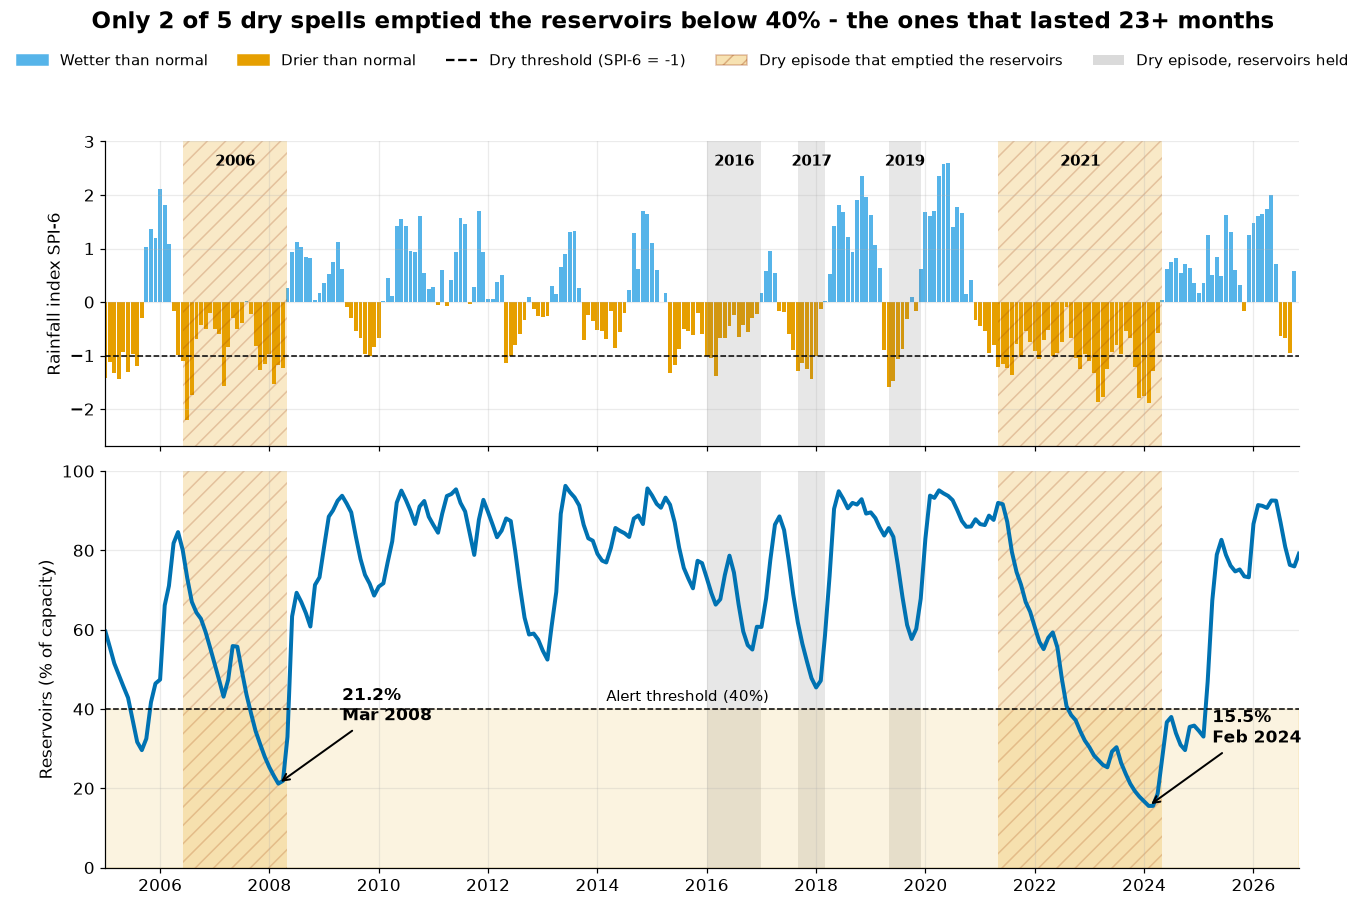

In [19]:
n_h, n_e = len(hydro), len(episodes)
fig, ax = plt.subplots(2, 1, figsize=(14, 8.8), sharex=True, gridspec_kw={"height_ratios": [1, 1.3], "hspace": .07})
x = monthly.index
ax[0].bar(x, monthly.spi6, width=26, color=np.where(monthly.spi6 >= 0, SKY, ORANGE))
ax[0].axhline(DRY_SPI, color="black", ls="--", lw=1)
ax[0].set_ylim(-2.7, 3.0); ax[0].set_ylabel("Rainfall index SPI-6")

for (o, e_), mn in zip(zip(onsets, end_dates), episodes["Min reservoir %"]):
    for a in ax:
        a.axvspan(o, e_, facecolor=ORANGE if mn < RES_ALERT else GREY, alpha=.22 if mn < RES_ALERT else .16,
                  hatch="//" if mn < RES_ALERT else None, edgecolor=BROWN, lw=0)
    ax[0].text(o + (e_ - o) / 2, 2.55, f"{o:%Y}", ha="center", fontsize=10, weight="bold")

ax[1].plot(x, monthly.res, color=BLUE, lw=2.6)
ax[1].axhspan(0, RES_ALERT, color=ORANGE, alpha=.12); ax[1].axhline(RES_ALERT, color="black", ls="--", lw=1)
ax[1].text(x[int(len(x) * .42)], RES_ALERT + 2, f"Alert threshold ({RES_ALERT}%)", fontsize=10)
for o, e_ in zip(onsets, end_dates):
    w = monthly.res.loc[o:e_ + pd.DateOffset(months=12)]
    if w.min() < RES_ALERT:
        t = w.idxmin()
        ax[1].annotate(f"{w.min():.1f}%\n{t:%b %Y}", (t, w.min()), xytext=(t + pd.DateOffset(months=14), w.min() + 16),
                       arrowprops=dict(arrowstyle="->", lw=1.3), fontsize=11, weight="bold")
ax[1].set_ylim(0, 100); ax[1].set_ylabel("Reservoirs (% of capacity)"); ax[1].set_xlim(x.min(), x.max())
ax[1].xaxis.set_major_locator(mdates.YearLocator(2)); ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

fig.suptitle(f"Only {n_h} of {n_e} dry spells emptied the reservoirs below {RES_ALERT}% - the ones that lasted {hydro['Duration [m]'].min():.0f}+ months",
             fontsize=15, weight="bold", y=.995)
fig.legend(handles=[Patch(color=SKY, label="Wetter than normal"), Patch(color=ORANGE, label="Drier than normal"),
                    Line2D([], [], color="black", ls="--", label=f"Dry threshold (SPI-6 = {DRY_SPI:.0f})"),
                    Patch(facecolor=ORANGE, alpha=.3, hatch="//", edgecolor=BROWN, label="Dry episode that emptied the reservoirs"),
                    Patch(facecolor=GREY, alpha=.25, label="Dry episode, reservoirs held")],
           loc="upper center", ncol=5, bbox_to_anchor=(.5, .965), frameon=False, fontsize=10)
fig.subplots_adjust(top=.86)
fig.savefig(os.path.join(FIG_DIR, "fig1_episodes.png"), dpi=200, bbox_inches="tight"); plt.show(); plt.close(fig)

### Figure 2. Duration, not intensity, decides

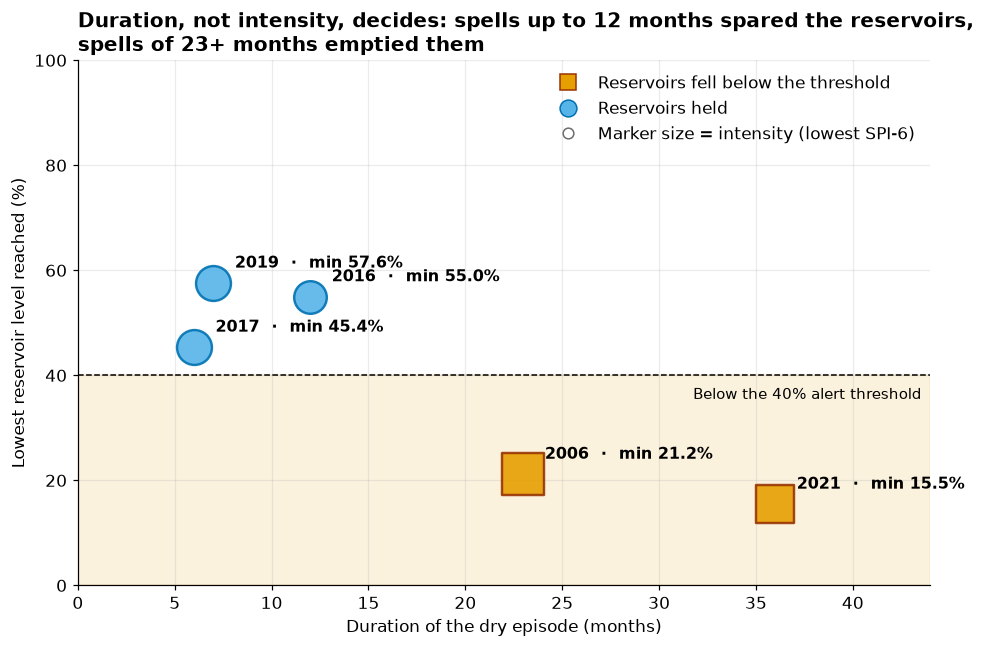

In [20]:
fig, ax = plt.subplots(figsize=(10, 6.2))
ax.axhspan(0, RES_ALERT, color=ORANGE, alpha=.13); ax.axhline(RES_ALERT, color="black", ls="--", lw=1)
ax.text(.99, RES_ALERT - 4.5, f"Below the {RES_ALERT}% alert threshold", transform=ax.get_yaxis_transform(), ha="right", fontsize=10)
for _, r in episodes.iterrows():
    h = r["Min reservoir %"] < RES_ALERT
    ax.scatter(r["Duration [m]"], r["Min reservoir %"], s=-r["Min SPI-6"] * 330, marker="s" if h else "o",
               color=ORANGE if h else SKY, edgecolor=BROWN if h else BLUE, linewidth=1.6, alpha=.9, zorder=3)
    ax.annotate(f"{r['Dry onset'][:4]}  ·  min {r['Min reservoir %']:.1f}%", (r["Duration [m]"], r["Min reservoir %"]),
                xytext=(14, 10), textcoords="offset points", fontsize=10.5, weight="bold")
ax.set_xlabel("Duration of the dry episode (months)"); ax.set_ylabel("Lowest reservoir level reached (%)")
ax.set_ylim(0, 100); ax.set_xlim(0, episodes["Duration [m]"].max() + 8)
ax.legend(handles=[Line2D([], [], marker="s", color=ORANGE, mec=BROWN, ls="", ms=11, label="Reservoirs fell below the threshold"),
                   Line2D([], [], marker="o", color=SKY, mec=BLUE, ls="", ms=11, label="Reservoirs held"),
                   Line2D([], [], marker="o", color="white", mec=GREY, ls="", ms=7, label="Marker size = intensity (lowest SPI-6)")],
          loc="upper right", frameon=False)
ax.set_title(f"Duration, not intensity, decides: spells up to {held['Duration [m]'].max():.0f} months spared the reservoirs,\n"
             f"spells of {hydro['Duration [m]'].min():.0f}+ months emptied them", loc="left")
fig.savefig(os.path.join(FIG_DIR, "fig2_duration.png"), dpi=200, bbox_inches="tight"); plt.show(); plt.close(fig)

### Figure 3. The chain of delays in the deepest drought

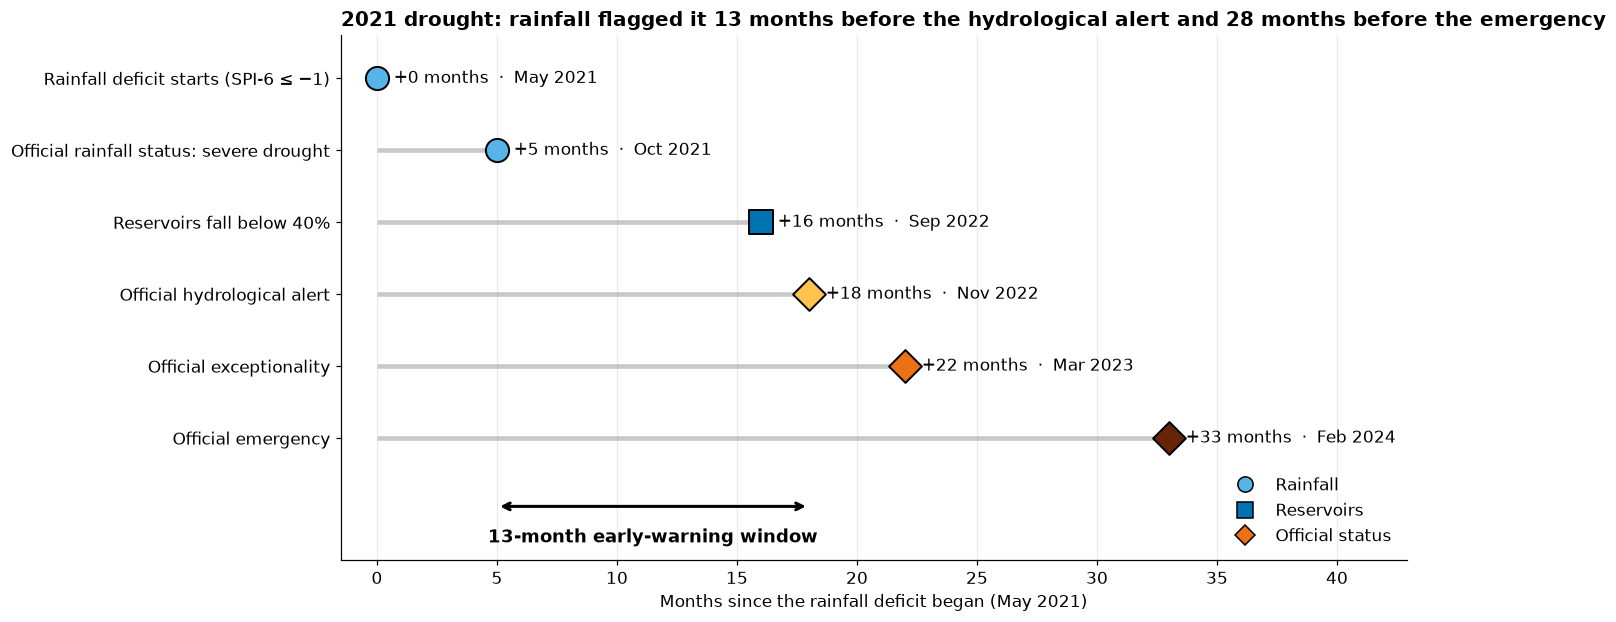

In [21]:
stages = [("Rainfall deficit starts (SPI-6 ≤ −1)", 0, "o", SKY, "Rainfall"),
          ("Official rainfall status: severe drought", main["Official rain: severe [m]"], "o", SKY, "Rainfall"),
          (f"Reservoirs fall below {RES_ALERT}%", main["Reservoirs <40% [m]"], "s", BLUE, "Reservoirs"),
          ("Official hydrological alert", main["Official hydro: alert [m]"], "D", HYD[2][1], "Official status"),
          ("Official exceptionality", main["Official hydro: exceptionality [m]"], "D", HYD[3][1], "Official status"),
          ("Official emergency", main["Official hydro: emergency [m]"], "D", HYD[5][1], "Official status")]
stages = sorted([s_ for s_ in stages if pd.notna(s_[1])], key=lambda s_: s_[1])
y = np.arange(len(stages))[::-1]

fig, ax = plt.subplots(figsize=(12.5, 6.2))
ax.hlines(y, 0, [s_[1] for s_ in stages], color="#C8C8C8", lw=3, zorder=1)
for (lab, lg, mk, col, _), yy in zip(stages, y):
    ax.scatter(lg, yy, s=230, marker=mk, color=col, edgecolor="black", linewidth=1.3, zorder=3)
    ax.text(lg + .7, yy, f"+{lg:.0f} months  ·  {main_o + pd.DateOffset(months=int(lg)):%b %Y}", va="center", fontsize=11)
ax.set_yticks(y, [s_[0] for s_ in stages]); ax.set_xlim(-1.5, stages[-1][1] * 1.3); ax.set_ylim(-1.7, len(stages) - .4)
ax.grid(axis="y", alpha=0); ax.set_xlabel(f"Months since the rainfall deficit began ({main_o:%b %Y})")

a1, a2, em = main["Official rain: severe [m]"], main["Official hydro: alert [m]"], main["Official hydro: emergency [m]"]
if pd.notna(a1) and pd.notna(a2):
    ax.annotate("", xy=(a2, -.95), xytext=(a1, -.95), arrowprops=dict(arrowstyle="<->", lw=2))
    ax.text((a1 + a2) / 2, -1.45, f"{a2 - a1:.0f}-month early-warning window", ha="center", fontsize=11.5, weight="bold")
ax.legend(handles=[Line2D([], [], marker="o", color=SKY, mec="black", ls="", ms=10, label="Rainfall"),
                   Line2D([], [], marker="s", color=BLUE, mec="black", ls="", ms=10, label="Reservoirs"),
                   Line2D([], [], marker="D", color=HYD[3][1], mec="black", ls="", ms=9, label="Official status")],
          loc="lower right", frameon=False)
ax.set_title(f"{main['Dry onset'][:4]} drought: rainfall flagged it {a2 - a1:.0f} months before the hydrological alert and {em - a1:.0f} months before the emergency", loc="left")
fig.savefig(os.path.join(FIG_DIR, "fig3_chain.png"), dpi=200, bbox_inches="tight"); plt.show(); plt.close(fig)

### Figure 4. Official status: the rainfall warning came first, the hydrological status followed the reservoirs

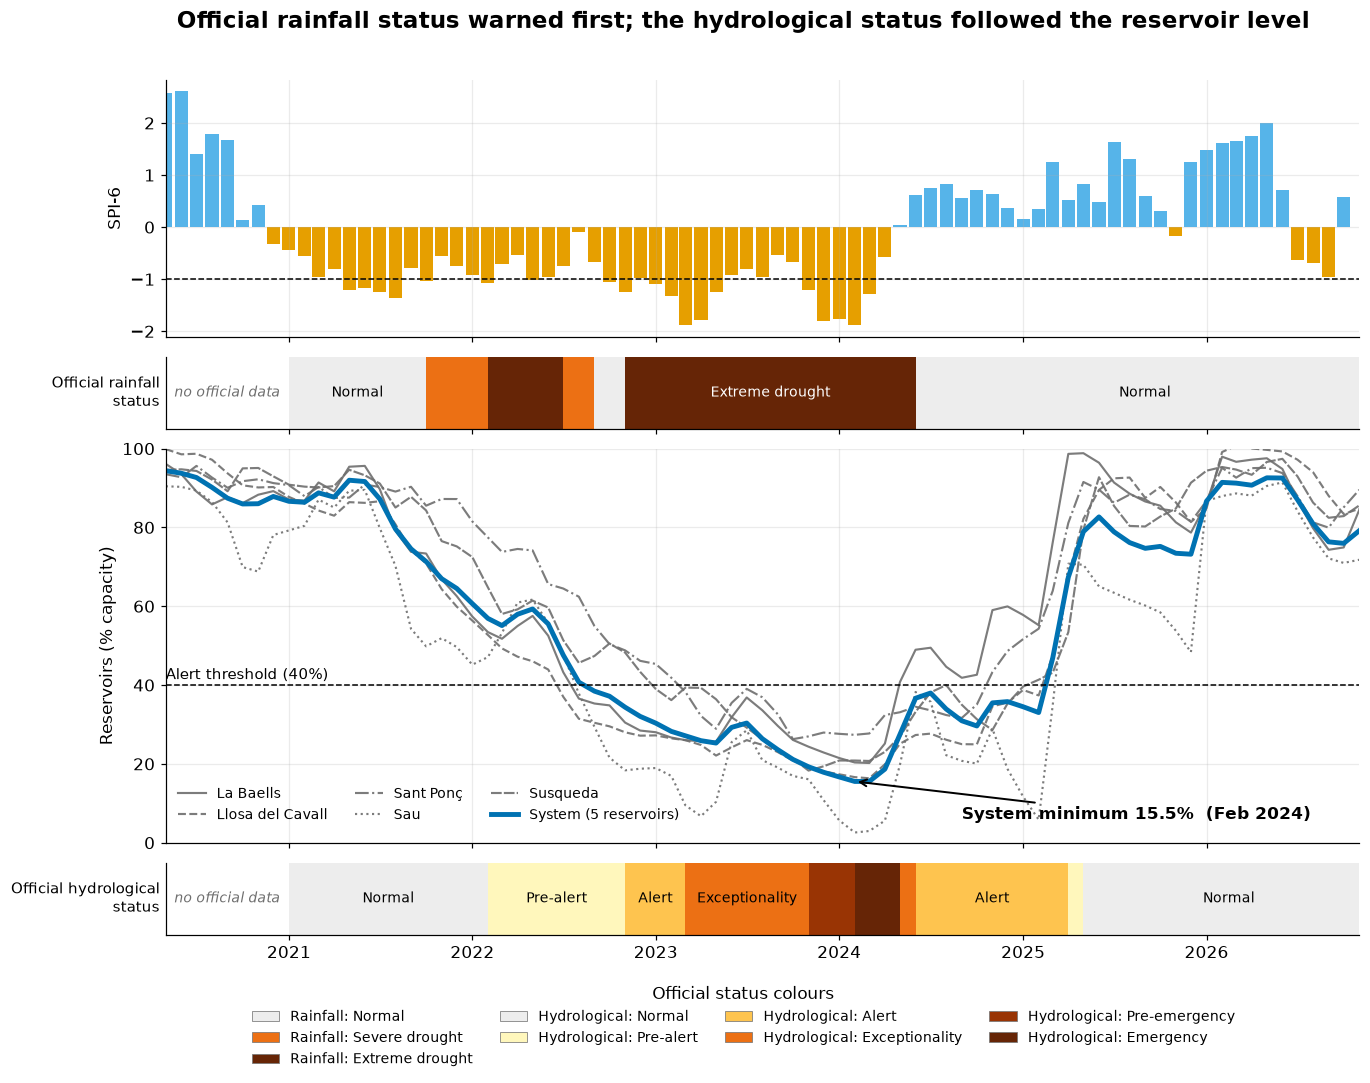

In [22]:
z0, z1 = main_o - pd.DateOffset(months=12), monthly.index.max()
fig, ax = plt.subplots(4, 1, figsize=(14, 10.5), sharex=True, gridspec_kw={"height_ratios": [1.5, .42, 2.3, .42], "hspace": .1})
z = monthly.loc[z0:z1]
ax[0].bar(z.index, z.spi6, width=26, color=np.where(z.spi6 >= 0, SKY, ORANGE)); ax[0].axhline(DRY_SPI, color="black", ls="--", lw=1)
ax[0].set_ylabel("SPI-6")

def strip(a, series, pal, label):
    for s0, s1, v in run_blocks(series.loc[z0:z1]):
        a.axvspan(s0, s1, color=pal[v][1], lw=0)
        if months_between(s0, s1) >= len(pal[v][0]) * .45:             # label only if it fits inside the block
            a.text(s0 + (s1 - s0) / 2, .5, pal[v][0], ha="center", va="center", fontsize=9, color="white" if v >= (4 if pal is HYD else 2) else "black")
    first = series.first_valid_index()
    if first is not None and first > z0:
        a.text(z0 + (first - z0) / 2, .5, "no official data", ha="center", va="center", fontsize=9, style="italic", color=GREY)
    a.set_yticks([]); a.set_ylabel(label, rotation=0, ha="right", va="center", fontsize=10); a.set_ylim(0, 1); a.grid(False)

strip(ax[1], monthly.plu, PLU, "Official rainfall\nstatus")
for (nm, col), ls in zip(resp.loc[z0:z1].items(), ["-", "--", "-.", ":", (0, (5, 1))]):
    ax[2].plot(col.index, col, color=GREY, lw=1.4, ls=ls, alpha=.9, label=nm)
ax[2].plot(z.index, z.res, color=BLUE, lw=3.2, label="System (5 reservoirs)")
ax[2].axhline(RES_ALERT, color="black", ls="--", lw=1); ax[2].text(z0, RES_ALERT + 1.5, f"Alert threshold ({RES_ALERT}%)", fontsize=10)
t = z.res.idxmin(); ax[2].annotate(f"System minimum {z.res.min():.1f}%  ({t:%b %Y})", (t, z.res.min()), xytext=(t + pd.DateOffset(months=7), 6),
                                   arrowprops=dict(arrowstyle="->", lw=1.3), fontsize=11, weight="bold")
ax[2].set_ylim(0, 100); ax[2].set_ylabel("Reservoirs (% capacity)"); ax[2].legend(loc="lower left", ncol=3, frameon=False, fontsize=9, bbox_to_anchor=(0, .02))
strip(ax[3], monthly.hyd, HYD, "Official hydrological\nstatus")
ax[3].xaxis.set_major_locator(mdates.YearLocator()); ax[3].xaxis.set_major_formatter(mdates.DateFormatter("%Y")); ax[3].set_xlim(z0, z1)
hp = [Patch(facecolor=PLU[i][1], edgecolor="#777", linewidth=.5, label=f"Rainfall: {PLU[i][0]}") for i in sorted(monthly.plu.dropna().astype(int).unique())]
hp += [Patch(facecolor=HYD[i][1], edgecolor="#777", linewidth=.5, label=f"Hydrological: {HYD[i][0]}") for i in sorted(monthly.hyd.dropna().astype(int).unique())]
fig.legend(handles=hp, loc="lower center", ncol=4, frameon=False, fontsize=9, bbox_to_anchor=(.5, .015), title="Official status colours")
fig.suptitle("Official rainfall status warned first; the hydrological status followed the reservoir level", fontsize=15, weight="bold", y=.94)
fig.subplots_adjust(bottom=.14)
fig.savefig(os.path.join(FIG_DIR, "fig4_official_status.png"), dpi=200, bbox_inches="tight"); plt.show(); plt.close(fig)

### Figure 5. Where it rained less: the deficit hit the whole territory
Rainfall of the deficit period compared with each station's normal, interpolated between stations. Squares are the reservoirs, with the minimum level they reached.

Outline skipped: GEOSException TopologyException: side location conflict at 0.82706072727272717 40.907277818181818. This can occur if the input geometry is invalid.


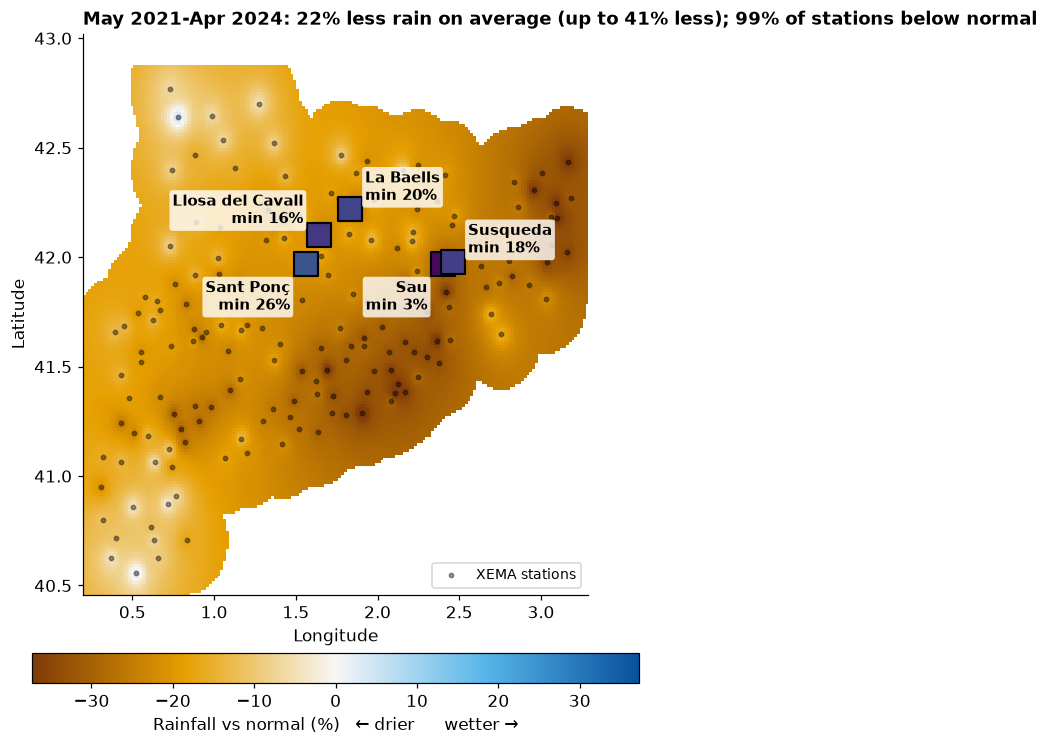

In [23]:
lat_c, lon_c = pick(stations, "LATITUD", "LAT", "LATITUDE"), pick(stations, "LONGITUD", "LON", "LONGITUDE")
dur_m = int(main["Duration [m]"]) if pd.notna(main["Duration [m]"]) else months_between(main_o, monthly.index.max())
win = pd.date_range(main_o, periods=dur_m, freq="MS")

clim = P_all.groupby(P_all.index.month).mean()
Pw = P_all.reindex(win)
Cw = clim.reindex(win.month).set_axis(win).where(Pw.notna())
anom = ((Pw.sum() / Cw.sum() - 1) * 100)[Pw.notna().mean() >= .8].rename(index=str).rename("a")
coords = (stations.drop_duplicates(s_id).assign(k=lambda x: x[s_id].astype(str)).set_index("k")[[lon_c, lat_c]]
          .apply(pd.to_numeric, errors="coerce"))
pts = coords.join(anom, how="inner").dropna()

# smooth surface (inverse-distance weighting, computed by blocks of rows to keep memory small)
X = np.linspace(pts[lon_c].min() - .1, pts[lon_c].max() + .1, 180); Y = np.linspace(pts[lat_c].min() - .1, pts[lat_c].max() + .1, 180)
gx, gy = np.meshgrid(X, Y)
xs, ys, av = (pts[lon_c].values.astype("float32"), pts[lat_c].values.astype("float32"), pts.a.values.astype("float32"))
Z = np.full(gx.shape, np.nan, dtype="float32"); dmin = np.full(gx.shape, np.inf, dtype="float32")
for i in range(0, gx.shape[0], 15):
    d2 = (gx[i:i + 15, :, None].astype("float32") - xs) ** 2 + (gy[i:i + 15, :, None].astype("float32") - ys) ** 2
    w = 1 / (d2 + 1e-6); Z[i:i + 15] = (w * av).sum(-1) / w.sum(-1); dmin[i:i + 15] = np.sqrt(d2.min(-1))

outline = None                                              # Catalonia outline from the team's ICGC file (optional)
if USE_GEO and find_file(COMARQUES_JSON, COMARQUES_GLOB):
    try:
        import geopandas as gpd, shapely
        outline = gpd.read_file(find_file(COMARQUES_JSON, COMARQUES_GLOB)).to_crs(4326).geometry.unary_union
        Z[~shapely.contains_xy(outline.simplify(0.005), gx.ravel(), gy.ravel()).reshape(gx.shape)] = np.nan
    except Exception as e:
        print("Outline skipped:", type(e).__name__, e); outline = None
if outline is None:
    Z[dmin > .25] = np.nan                                  # fallback: footprint of the stations

rmin = resp.loc[main_o:main_o + pd.DateOffset(months=dur_m + 12)].min()
fig, ax = plt.subplots(figsize=(9.5, 8.6))
v = max(np.nanpercentile(np.abs(pts.a), 95), 10)
mesh = ax.pcolormesh(gx, gy, Z, cmap=DRY_WET, vmin=-v, vmax=v, shading="auto")
if outline is not None:
    gpd.GeoSeries([outline]).boundary.plot(ax=ax, color="#333", lw=.9)
ax.scatter(pts[lon_c], pts[lat_c], s=8, c="black", alpha=.4, label="XEMA stations")
for rx, (lab, lon, lat, dx, dy, ha) in RES_XY.items():
    mn = rmin.get(lab, np.nan)
    ax.scatter(lon, lat, s=260, c=[mn], cmap="viridis", vmin=0, vmax=100, edgecolor="black", linewidth=1.4, marker="s", zorder=5)
    ax.annotate(f"{lab}\nmin {mn:.0f}%", (lon, lat), xytext=(dx, dy), textcoords="offset points", ha=ha, fontsize=9.5, weight="bold", zorder=6,
                bbox=dict(boxstyle="round,pad=.2", fc="white", alpha=.8, lw=0))
ax.set_ylim(pts[lat_c].min() - .1, pts[lat_c].max() + .25); ax.set_aspect(1 / np.cos(np.radians(41.7))); ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude"); ax.grid(False)
cb = plt.colorbar(mesh, ax=ax, orientation="horizontal", pad=.08, shrink=.75); cb.set_label("Rainfall vs normal (%)   ← drier      wetter →")
ax.legend(loc="lower right", frameon=True, fontsize=9)
ax.set_title(f"{win[0]:%b %Y}-{win[-1]:%b %Y}: {-pts.a.mean():.0f}% less rain on average (up to {-pts.a.min():.0f}% less); {(pts.a < 0).mean():.0%} of stations below normal", loc="left", fontsize=12)
fig.savefig(os.path.join(FIG_DIR, "fig5_map_rainfall.png"), dpi=200, bbox_inches="tight"); plt.show(); plt.close(fig)

## 8. Maps by municipality and comarca

Using: ../data\raw\divisions-administratives-v2r1-municipis-1000000-20250730.json | ../data\raw\divisions-administratives-v2r1-comarques-250000-20250730.json
Municipalities in the outline: 947 | with official data: 630
Comarques in the outline: 43 | with SPI-6: 41


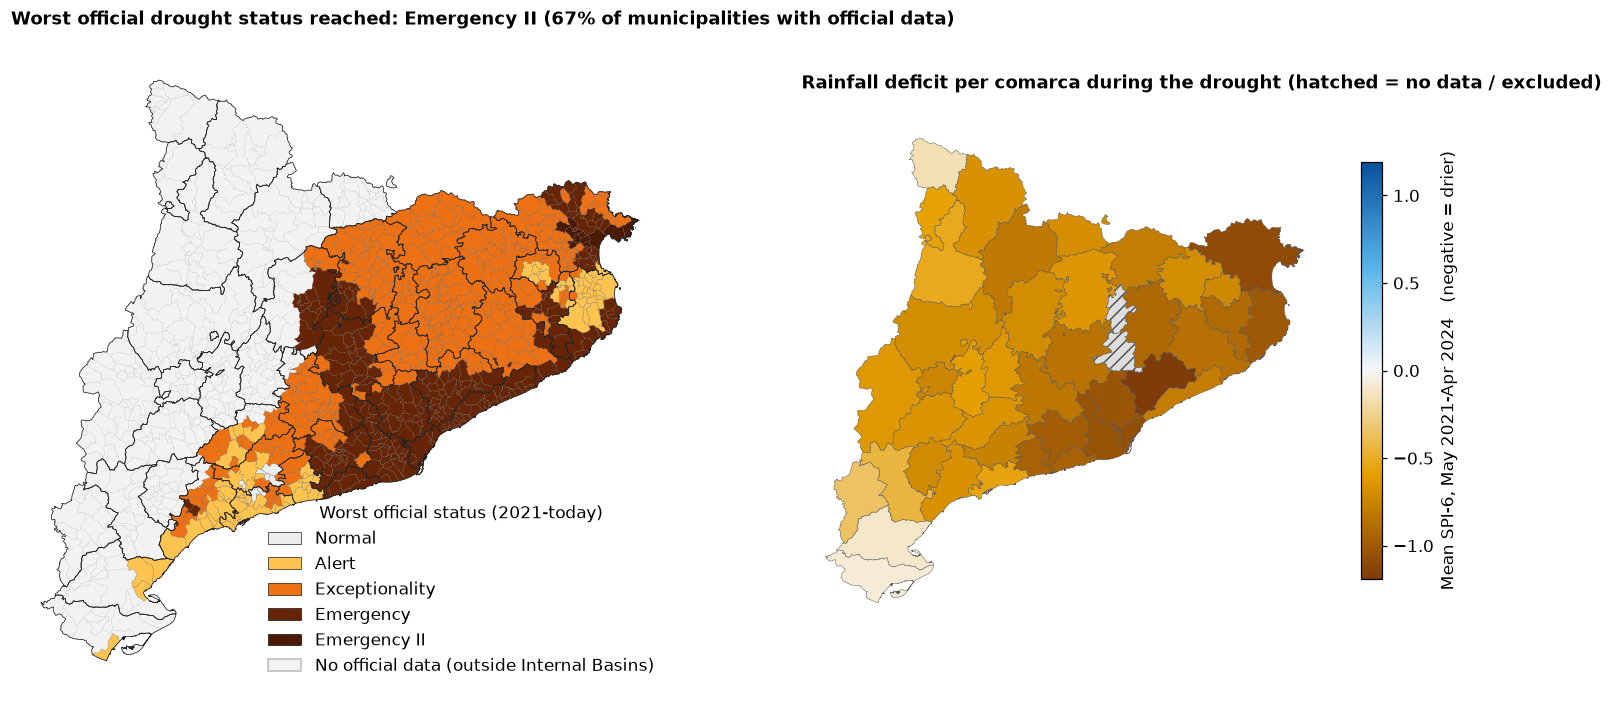

In [24]:
try:
    assert USE_GEO, "USE_GEO = False"
    import geopandas as gpd
    p_m, p_c = find_file(MUNIS_JSON, MUNIS_GLOB), find_file(COMARQUES_JSON, COMARQUES_GLOB)
    assert p_m and p_c, (f"Outline files not found.\n  working dir : {os.getcwd()}\n  searched in : {DATA_DIRS} (+ one sub-folder deep)\n"
                         f"  looking for : {MUNIS_JSON}  /  {COMARQUES_JSON}\n"
                         "  -> copy both .json files from the team repo into ../data (or add their folder to DATA_DIRS) and re-run this cell")
    print("Using:", p_m, "|", p_c)

    up = lambda g: g.rename(columns=lambda c: c if c == "geometry" else c.upper())
    gm, gc = up(gpd.read_file(p_m)).to_crs(25831), up(gpd.read_file(p_c)).to_crs(25831)
    c_gm = next(c for c in gm.columns if re.search(r"^CODI.*MUN", c))
    c_gc = next(c for c in gc.columns if re.search(r"^CODI.*COMAR", c))
    c_gn = next((c for c in gc.columns if re.search(r"^NOM.*COMAR", c)), None)

    # ---- municipalities: worst official hydrological status since 2021 (join on the 5-digit INE key, robust to the 6th check digit / lost zeros)
    peak = mmon.dropna(subset=["hyd"]).assign(k5=lambda d: key5(d.municipi_code)).groupby("k5").hyd.max()
    gm["k5"] = key5(gm[c_gm], six=gm[c_gm].astype(str).str.len().max() >= 6).values
    gm["hyd_peak"] = gm.k5.map(peak)
    print(f"Municipalities in the outline: {len(gm)} | with official data: {gm.hyd_peak.notna().sum()}")
    assert gm.hyd_peak.notna().any(), f"No municipality matched. Outline codes look like {gm[c_gm].head(3).tolist()}, status codes like {mmon.municipi_code.head(3).tolist()}"

    # ---- comarques: mean SPI-6 during the deepest drought
    spi_ep = out[(out.month >= win[0]) & (out.month <= win[-1])].groupby(KEY).spi6.mean()
    gc["spi_ep"] = pd.to_numeric(gc[c_gc], errors="coerce").map(spi_ep) if KEY == "comarca_code" else gc[c_gn].map(spi_ep)
    print(f"Comarques in the outline: {len(gc)} | with SPI-6: {gc.spi_ep.notna().sum()}")
    assert gc.spi_ep.notna().any(), f"No comarca matched (KEY={KEY}). Outline codes: {gc[c_gc].head(3).tolist()}, SPI keys: {list(spi_ep.index[:3])}"
    vlim = max(float(gc.spi_ep.abs().max()), 1.0)

    fig, ax = plt.subplots(1, 2, figsize=(17, 8.2))
    gm[gm.hyd_peak.isna()].plot(ax=ax[0], color="#F2F2F2", edgecolor="#BBBBBB", linewidth=.15)
    d_ = gm[gm.hyd_peak.notna()]
    d_.plot(ax=ax[0], color=d_.hyd_peak.map(lambda v: HYD[int(v)][1]).tolist(), edgecolor="#555", linewidth=.15)
    gc.boundary.plot(ax=ax[0], color="#222", linewidth=.5)
    ax[0].legend(handles=[Patch(facecolor=HYD[i][1], edgecolor="black", linewidth=.4, label=HYD[i][0]) for i in sorted(gm.hyd_peak.dropna().astype(int).unique())]
                 + [Patch(facecolor="#F2F2F2", edgecolor="#BBBBBB", label="No official data (outside Internal Basins)")], title="Worst official status (2021-today)", loc="lower right", frameon=False)
    top = int(gm.hyd_peak.max())
    ax[0].set_title(f"Worst official drought status reached: {HYD[top][0]} ({gm.hyd_peak.notna().mean():.0%} of municipalities with official data)", loc="left", fontsize=11.5)

    gc.plot(column="spi_ep", cmap=DRY_WET, vmin=-vlim, vmax=vlim, legend=True, missing_kwds={"color": "#DDDDDD", "edgecolor": "#555", "hatch": "///"}, edgecolor="#555", linewidth=.3, ax=ax[1],
            legend_kwds={"label": f"Mean SPI-6, {win[0]:%b %Y}-{win[-1]:%b %Y}   (negative = drier)", "shrink": .6})
    ax[1].set_title("Rainfall deficit per comarca during the drought (hatched = no data / excluded)", loc="left", fontsize=11.5)
    for a in ax: a.set_axis_off()
    fig.savefig(os.path.join(FIG_DIR, "fig6_maps_municipality_comarca.png"), dpi=200, bbox_inches="tight"); plt.show(); plt.close(fig)
except ImportError as e:
    print("geopandas is not installed (pip install geopandas):", e)
except AssertionError as e:
    print("Maps skipped:", e)          # any other error is NOT swallowed on purpose: you see the real traceback
